In [1]:
"""Integrate advanced monitoring and logging into ML pipelines, capturing model performance metrics,
 data drift indicators, and system health statistics using tools like Prometheus, Grafana, and ELK Stack for proactive maintenance."""

'Integrate advanced monitoring and logging into ML pipelines, capturing model performance metrics,\n data drift indicators, and system health statistics using tools like Prometheus, Grafana, and ELK Stack for proactive maintenance.'

In [2]:
# import libraries and load pharmacy sales dataset for monitoring
import os
import time
import json
import logging
from datetime import datetime
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
from scipy.stats import ks_2samp
from sklearn.model_selection import train_test_split
from sklearn.ensemble import RandomForestRegressor
from sklearn.metrics import mean_squared_error, mean_absolute_error, r2_score
from prometheus_client import CollectorRegistry, Gauge, Counter, Histogram, generate_latest

data_path = 'global_pharmacy_sales_data.csv' if os.path.exists('global_pharmacy_sales_data.csv') else '../global_pharmacy_sales_data.csv'
df = pd.read_csv(data_path)
print("pharmacy sales dataset loaded for monitoring pipeline. shape:", df.shape)

pharmacy sales dataset loaded for monitoring pipeline. shape: (177990, 14)


In [3]:
# clean columns and separate baseline data from production monitoring stream
sample_df = df.sample(n=6000, random_state=42).reset_index(drop=True)
features = ['unit_price', 'stock_level', 'expiry_days_remaining', 'covid_flag', 'year', 'month']
target = 'units_sold'

train_baseline, prod_stream = train_test_split(sample_df, test_size=0.35, random_state=42)

print(f"baseline reference size: {len(train_baseline)}")
print(f"production monitoring stream size: {len(prod_stream)}")
print("monitoring features:", features)

baseline reference size: 3900
production monitoring stream size: 2100
monitoring features: ['unit_price', 'stock_level', 'expiry_days_remaining', 'covid_flag', 'year', 'month']


In [4]:
# train baseline regression model for pharmacy sales demand
X_base = train_baseline[features]
y_base = train_baseline[target]

model = RandomForestRegressor(n_estimators=50, max_depth=8, random_state=42, n_jobs=-1)
model.fit(X_base, y_base)

base_preds = model.predict(X_base)
base_r2 = r2_score(y_base, base_preds)
base_mse = mean_squared_error(y_base, base_preds)

print("baseline pharmacy sales model trained successfully.")
print(f"baseline r2 score: {base_r2:.4f}")
print(f"baseline mse: {base_mse:.2f}")

baseline pharmacy sales model trained successfully.
baseline r2 score: 0.9557
baseline mse: 5474.09


In [5]:
# setup structured elk logging configuration for pharmacy pipeline
class JsonLogFormatter(logging.Formatter):
    def format(self, record):
        log_record = {
            "timestamp": datetime.utcnow().isoformat() + "Z",
            "service": "pharmacy_sales_ml_pipeline",
            "level": record.levelname,
            "message": record.getMessage(),
            "logger": record.name
        }
        if hasattr(record, 'extra_data'):
            log_record["data"] = record.extra_data
        return json.dumps(log_record)

elk_logger = logging.getLogger("elk_pharmacy_pipeline")
elk_logger.setLevel(logging.INFO)
elk_logger.handlers.clear()

log_file = "ml_pipeline_elk.log"
file_handler = logging.FileHandler(log_file, mode='w')
file_handler.setFormatter(JsonLogFormatter())
elk_logger.addHandler(file_handler)

elk_logger.info("elk structured logger initialized successfully", extra={"extra_data": {"status": "active"}})
print("structured json logging configured for elk stack ingestion.")

structured json logging configured for elk stack ingestion.


C:\Users\Lenovo\AppData\Local\Temp\ipykernel_21316\3217470660.py:5: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  "timestamp": datetime.utcnow().isoformat() + "Z",


In [6]:
# initialize prometheus metrics for model performance and system health
registry = CollectorRegistry()

metric_requests = Counter(
    'pharmacy_prediction_requests_total',
    'total count of pharmacy sales prediction requests',
    registry=registry
)
metric_latency = Histogram(
    'pharmacy_inference_latency_seconds',
    'prediction latency in seconds',
    buckets=(0.0005, 0.001, 0.005, 0.01, 0.05),
    registry=registry
)
metric_mse = Gauge(
    'pharmacy_model_mse',
    'current mean squared error of sales model',
    registry=registry
)
metric_mae = Gauge(
    'pharmacy_model_mae',
    'current mean absolute error of sales model',
    registry=registry
)
metric_drift_ks = Gauge(
    'pharmacy_data_drift_ks_stat',
    'kolmogorov smirnov drift statistic',
    ['feature_name'],
    registry=registry
)
metric_drift_pval = Gauge(
    'pharmacy_data_drift_pvalue',
    'kolmogorov smirnov drift p-value',
    ['feature_name'],
    registry=registry
)
metric_memory_usage = Gauge(
    'pharmacy_system_memory_usage_mb',
    'simulated memory usage in megabytes',
    registry=registry
)

print("prometheus metrics initialized for performance, drift, and system health.")

prometheus metrics initialized for performance, drift, and system health.


In [7]:
# define data drift detection function using statistical tests
def detect_data_drift(reference_df, current_df, feature_cols, alpha=0.05):
    drift_report = {}
    for col in feature_cols:
        stat, p_val = ks_2samp(reference_df[col], current_df[col])
        is_drifted = p_val < alpha
        
        drift_report[col] = {
            "ks_statistic": round(float(stat), 4),
            "p_value": round(float(p_val), 4),
            "drift_detected": bool(is_drifted)
        }
        metric_drift_ks.labels(feature_name=col).set(stat)
        metric_drift_pval.labels(feature_name=col).set(p_val)
        
        if is_drifted:
            elk_logger.warning(
                f"data drift alert triggered for feature: {col}",
                extra={"extra_data": {"feature": col, "ks_stat": stat, "p_value": p_val}}
            )
    return drift_report

In [8]:
# simulate production inference stream with normal and drifted sales windows
normal_window = prod_stream.iloc[:len(prod_stream)//2].copy()

drifted_window = prod_stream.iloc[len(prod_stream)//2:].copy()
drifted_window['stock_level'] = drifted_window['stock_level'] * 0.75
drifted_window['unit_price'] = drifted_window['unit_price'] * 1.35
drifted_window['expiry_days_remaining'] = drifted_window['expiry_days_remaining'] * 0.80

print(f"normal production window records: {len(normal_window)}")
print(f"drifted production window records: {len(drifted_window)}")

normal production window records: 1050
drifted production window records: 1050


In [9]:
# process inference stream, record metrics, and log system statistics
monitoring_records = []

for window_idx, (window_name, window_df) in enumerate([("normal_sales_window", normal_window), ("drifted_sales_window", drifted_window)]):
    X_window = window_df[features]
    y_window = window_df[target]
    
    start_time = time.time()
    preds = model.predict(X_window)
    latency = (time.time() - start_time) / len(X_window)
    
    for _ in range(len(X_window)):
        metric_requests.inc()
        metric_latency.observe(latency)
        
    mse_val = mean_squared_error(y_window, preds)
    mae_val = mean_absolute_error(y_window, preds)
    r2_val = r2_score(y_window, preds)
    
    metric_mse.set(mse_val)
    metric_mae.set(mae_val)
    simulated_mem_mb = 160.0 + (window_idx * 18.0) + np.random.uniform(0.5, 2.5)
    metric_memory_usage.set(simulated_mem_mb)
    
    drift_results = detect_data_drift(train_baseline, window_df, features)
    drifted_count = sum(1 for v in drift_results.values() if v['drift_detected'])
    
    elk_logger.info(
        f"completed monitoring cycle for {window_name}",
        extra={"extra_data": {
            "window": window_name,
            "mse": mse_val,
            "mae": mae_val,
            "r2": r2_val,
            "latency_ms": latency * 1000,
            "memory_mb": simulated_mem_mb,
            "drifted_features": drifted_count
        }}
    )
    
    monitoring_records.append({
        "window": window_name,
        "mse": round(mse_val, 2),
        "mae": round(mae_val, 2),
        "r2": round(r2_val, 4),
        "latency_ms": round(latency * 1000, 4),
        "memory_mb": round(simulated_mem_mb, 2),
        "drifted_features": drifted_count
    })

print("sales stream monitoring completed across normal and drifted windows.")

C:\Users\Lenovo\AppData\Local\Temp\ipykernel_21316\3217470660.py:5: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  "timestamp": datetime.utcnow().isoformat() + "Z",
C:\Users\Lenovo\AppData\Local\Temp\ipykernel_21316\3217470660.py:5: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  "timestamp": datetime.utcnow().isoformat() + "Z",


sales stream monitoring completed across normal and drifted windows.


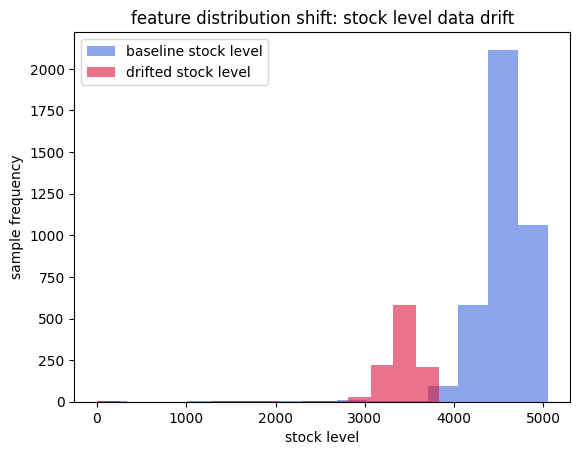

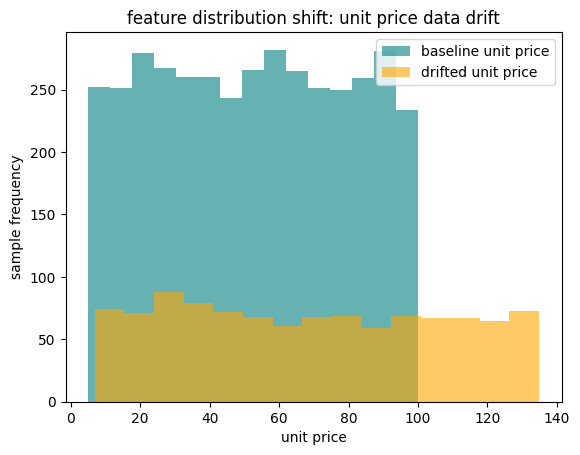

In [10]:
# plot data drift comparison for stock level and unit price
plt.hist(train_baseline['stock_level'], bins=15, alpha=0.6, label='baseline stock level', color='royalblue')
plt.hist(drifted_window['stock_level'], bins=15, alpha=0.6, label='drifted stock level', color='crimson')
plt.title('feature distribution shift: stock level data drift')
plt.xlabel('stock level')
plt.ylabel('sample frequency')
plt.legend()
plt.show()

plt.hist(train_baseline['unit_price'], bins=15, alpha=0.6, label='baseline unit price', color='teal')
plt.hist(drifted_window['unit_price'], bins=15, alpha=0.6, label='drifted unit price', color='orange')
plt.title('feature distribution shift: unit price data drift')
plt.xlabel('unit price')
plt.ylabel('sample frequency')
plt.legend()
plt.show()

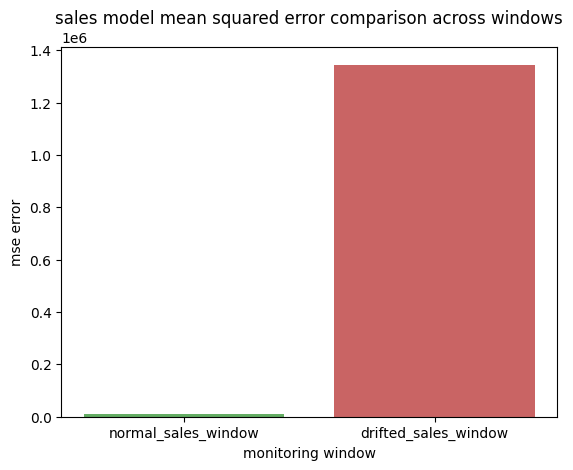

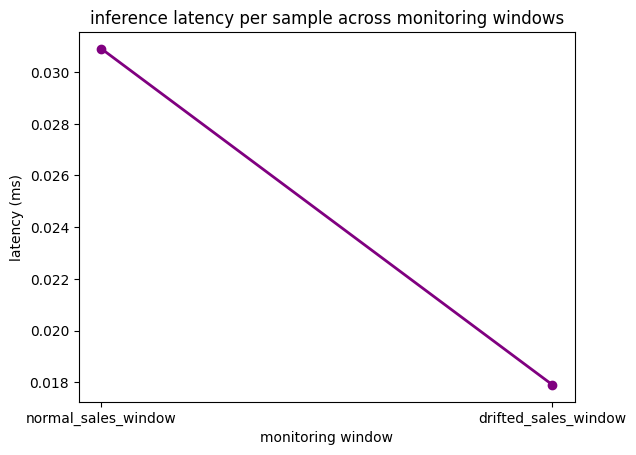

In [11]:
# plot model inference latency and error metrics over time
windows = [r['window'] for r in monitoring_records]
mse_values = [r['mse'] for r in monitoring_records]
latency_values = [r['latency_ms'] for r in monitoring_records]

plt.bar(windows, mse_values, color=['forestgreen', 'firebrick'], alpha=0.7)
plt.title('sales model mean squared error comparison across windows')
plt.xlabel('monitoring window')
plt.ylabel('mse error')
plt.show()

plt.plot(windows, latency_values, marker='o', color='purple', linewidth=2)
plt.title('inference latency per sample across monitoring windows')
plt.xlabel('monitoring window')
plt.ylabel('latency (ms)')
plt.show()

In [12]:
# export monitoring summary report and prometheus metric state
summary_table = pd.DataFrame(monitoring_records)
print("pharmacy sales ml pipeline monitoring dashboard summary:")
print(summary_table.to_string(index=False))

print("\nprometheus exposition metrics sample (head):")
raw_metrics = generate_latest(registry).decode('utf-8')
for line in raw_metrics.splitlines()[:18]:
    print(line)

print("\nlast structured log entry from elk log:")
with open(log_file, 'r') as f:
    last_log = f.readlines()[-1]
    print(json.dumps(json.loads(last_log), indent=2))

pharmacy sales ml pipeline monitoring dashboard summary:
              window        mse     mae      r2  latency_ms  memory_mb  drifted_features
 normal_sales_window   10723.23   69.33  0.9286      0.0309     161.92                 0
drifted_sales_window 1345347.03 1149.99 -9.2489      0.0179     178.68                 3

prometheus exposition metrics sample (head):
# HELP pharmacy_prediction_requests_total total count of pharmacy sales prediction requests
# TYPE pharmacy_prediction_requests_total counter
pharmacy_prediction_requests_total 2100.0
# HELP pharmacy_prediction_requests_created total count of pharmacy sales prediction requests
# TYPE pharmacy_prediction_requests_created gauge
pharmacy_prediction_requests_created 1.7951695298632376e+09
# HELP pharmacy_inference_latency_seconds prediction latency in seconds
# TYPE pharmacy_inference_latency_seconds histogram
pharmacy_inference_latency_seconds_bucket{le="0.0005"} 2100.0
pharmacy_inference_latency_seconds_bucket{le="0.001"} 21